In [2]:
print("Welcome to Product Review Sentiment Analysis!")
print("Our goal is to classify reviews as Positive, Negative, or Neutral.")

Welcome to Product Review Sentiment Analysis!
Our goal is to classify reviews as Positive, Negative, or Neutral.


In [6]:
import pandas as pd

df = pd.read_csv("Datafiniti_Amazon_Consumer_Reviews_of_Amazon_Products_May19.csv")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
print(df.columns.tolist())

Dataset loaded successfully!
Rows and columns: (28332, 24)
['id', 'dateAdded', 'dateUpdated', 'name', 'asins', 'brand', 'categories', 'primaryCategories', 'imageURLs', 'keys', 'manufacturer', 'manufacturerNumber', 'reviews.date', 'reviews.dateSeen', 'reviews.didPurchase', 'reviews.doRecommend', 'reviews.id', 'reviews.numHelpful', 'reviews.rating', 'reviews.sourceURLs', 'reviews.text', 'reviews.title', 'reviews.username', 'sourceURLs']


In [7]:
df.isnull().sum()

id                         0
dateAdded                  0
dateUpdated                0
name                       0
asins                      0
brand                      0
categories                 0
primaryCategories          0
imageURLs                  0
keys                       0
manufacturer               0
manufacturerNumber         0
reviews.date               0
reviews.dateSeen           0
reviews.didPurchase    28323
reviews.doRecommend    12246
reviews.id             28291
reviews.numHelpful     12217
reviews.rating             0
reviews.sourceURLs         0
reviews.text               0
reviews.title              0
reviews.username           5
sourceURLs                 0
dtype: int64

In [8]:
df.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
28327    False
28328    False
28329    False
28330    False
28331    False
Length: 28332, dtype: bool

In [9]:
print("Missing review texts:", df["reviews.text"].isnull().sum())
print("Missing ratings:", df["reviews.rating"].isnull().sum())

print("\nRating distribution:")
print(df["reviews.rating"].value_counts().sort_index())

df[["reviews.text", "reviews.rating"]].head(10)

Missing review texts: 0
Missing ratings: 0

Rating distribution:
reviews.rating
1      965
2      616
3     1206
4     5648
5    19897
Name: count, dtype: int64


,reviews.text,reviews.rating
0,I order 3 of them and one of the item is bad q...,3
1,Bulk is always the less expensive way to go fo...,4
2,Well they are not Duracell but for the price i...,5
3,Seem to work as well as name brand batteries a...,5
4,These batteries are very long lasting the pric...,5
5,Bought a lot of batteries for Christmas and th...,5
6,ive not had any problame with these batteries ...,5
7,Well if you are looking for cheap non-recharge...,5
8,These do not hold the amount of high power jui...,3
9,AmazonBasics AA AAA batteries have done well b...,4


In [10]:
def get_sentiment(rating):
    if rating <= 2:
        return "Negative"
    elif rating == 3:
        return "Neutral"
    else:
        return "Positive"

df["sentiment"] = df["reviews.rating"].apply(get_sentiment)

print(df["sentiment"].value_counts())

df[["reviews.text", "reviews.rating", "sentiment"]].head(10)

sentiment
Positive    25545
Negative     1581
Neutral      1206
Name: count, dtype: int64


,reviews.text,reviews.rating,sentiment
0,I order 3 of them and one of the item is bad q...,3,Neutral
1,Bulk is always the less expensive way to go fo...,4,Positive
2,Well they are not Duracell but for the price i...,5,Positive
3,Seem to work as well as name brand batteries a...,5,Positive
4,These batteries are very long lasting the pric...,5,Positive
5,Bought a lot of batteries for Christmas and th...,5,Positive
6,ive not had any problame with these batteries ...,5,Positive
7,Well if you are looking for cheap non-recharge...,5,Positive
8,These do not hold the amount of high power jui...,3,Neutral
9,AmazonBasics AA AAA batteries have done well b...,4,Positive


In [11]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["cleaned_text"] = df["reviews.text"].apply(clean_text)

df[["reviews.text", "cleaned_text"]].head(10)

,reviews.text,cleaned_text
0,I order 3 of them and one of the item is bad q...,i order of them and one of the item is bad qua...
1,Bulk is always the less expensive way to go fo...,bulk is always the less expensive way to go fo...
2,Well they are not Duracell but for the price i...,well they are not duracell but for the price i...
3,Seem to work as well as name brand batteries a...,seem to work as well as name brand batteries a...
4,These batteries are very long lasting the pric...,these batteries are very long lasting the pric...
5,Bought a lot of batteries for Christmas and th...,bought a lot of batteries for christmas and th...
6,ive not had any problame with these batteries ...,ive not had any problame with these batteries ...
7,Well if you are looking for cheap non-recharge...,well if you are looking for cheap nonrechargea...
8,These do not hold the amount of high power jui...,these do not hold the amount of high power jui...
9,AmazonBasics AA AAA batteries have done well b...,amazonbasics aa aaa batteries have done well b...


In [12]:
from sklearn.model_selection import train_test_split

X = df["cleaned_text"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 22665
Testing samples: 5667


In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

model = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=10000)),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [14]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 92.85 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.79      0.48      0.60       316
     Neutral       0.50      0.08      0.14       241
    Positive       0.94      1.00      0.97      5110

    accuracy                           0.93      5667
   macro avg       0.74      0.52      0.57      5667
weighted avg       0.91      0.93      0.91      5667


Confusion Matrix:
[[ 151    7  158]
 [  33   19  189]
 [   6   12 5092]]


In [15]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=10000)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model retrained with balanced classes!")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Model retrained with balanced classes!

Classification Report:
              precision    recall  f1-score   support

    Negative       0.56      0.79      0.66       316
     Neutral       0.25      0.68      0.37       241
    Positive       0.99      0.88      0.93      5110

    accuracy                           0.87      5667
   macro avg       0.60      0.79      0.65      5667
weighted avg       0.93      0.87      0.89      5667



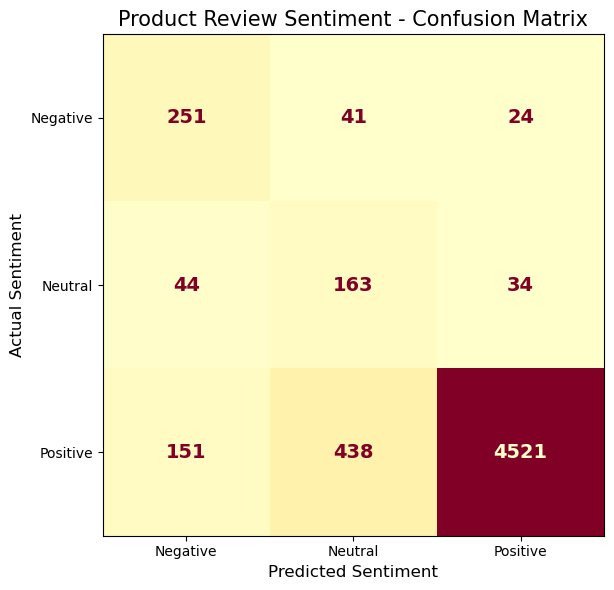

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["Negative", "Neutral", "Positive"],
    cmap="YlOrRd",
    values_format="d",
    colorbar=False,
    text_kw={"fontsize": 14, "fontweight": "bold"},
    ax=ax
)

plt.title("Product Review Sentiment - Confusion Matrix", fontsize=15)
plt.xlabel("Predicted Sentiment", fontsize=12)
plt.ylabel("Actual Sentiment", fontsize=12)
plt.tight_layout()
plt.show()

In [18]:
from sklearn.metrics import accuracy_score, f1_score

print("Model Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("Macro F1-Score:", round(f1_score(y_test, y_pred, average="macro"), 3))
print("Weighted F1-Score:", round(f1_score(y_test, y_pred, average="weighted"), 3))

Model Accuracy: 87.08 %
Macro F1-Score: 0.654
Weighted F1-Score: 0.894


In [19]:
import joblib

joblib.dump(model, "sentiment_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [20]:
results = df.copy()

results["predicted_sentiment"] = model.predict(
    df["cleaned_text"]
)

results[[
    "name",
    "categories",
    "reviews.text",
    "reviews.rating",
    "sentiment",
    "predicted_sentiment"
]].head()

,name,categories,reviews.text,reviews.rating,sentiment,predicted_sentiment
0,AmazonBasics AAA Performance Alkaline Batterie...,"AA,AAA,Health,Electronics,Health & Household,C...",I order 3 of them and one of the item is bad q...,3,Neutral,Neutral
1,AmazonBasics AAA Performance Alkaline Batterie...,"AA,AAA,Health,Electronics,Health & Household,C...",Bulk is always the less expensive way to go fo...,4,Positive,Positive
2,AmazonBasics AAA Performance Alkaline Batterie...,"AA,AAA,Health,Electronics,Health & Household,C...",Well they are not Duracell but for the price i...,5,Positive,Neutral
3,AmazonBasics AAA Performance Alkaline Batterie...,"AA,AAA,Health,Electronics,Health & Household,C...",Seem to work as well as name brand batteries a...,5,Positive,Positive
4,AmazonBasics AAA Performance Alkaline Batterie...,"AA,AAA,Health,Electronics,Health & Household,C...",These batteries are very long lasting the pric...,5,Positive,Positive


In [21]:
results.to_csv("sentiment_analysis_results.csv", index=False)

print("CSV exported successfully!")
print("Total records:", len(results))

CSV exported successfully!
Total records: 28332


In [22]:
import os

print(os.getcwd())
print(os.path.exists("sentiment_analysis_results.csv"))

C:\Users\pavit
True


In [23]:
import os
print(os.path.abspath("sentiment_analysis_results.csv"))

C:\Users\pavit\sentiment_analysis_results.csv
